# Stock Market Analysis_The Dow Jones Industrial Average (DJIA)

### The main Objectives for DJIA Analysis

***i. Trend & Price Regime Identification***

•	Evaluate Moving Average Structure

•	Identify Support & Resistance Zones

***ii. Volatility & Risk Quantification***

•	Track Rolling Volatility

•	Assess Intraday Noise

***iii. Macro & Sector Contribution Drivers***

•	Analyze Price-Weighted Impact

•	Sector Rotation Analysis

***iv. Valuation & Forecasting Frameworks***

•	Intrinsic & Relative Valuation: 

•	Scenario Modeling: 

## Step 1: Import libraries

In [201]:
import datetime
import matplotlib.pyplot as plt
import numpy as np 
import pandas as pd
import seaborn as sns
import scipy.stats as stats
from scipy.optimize import minimize
import statsmodels.api as sm
import yfinance as yf
from mpl_toolkits.mplot3d import Axes3D

## Step 2: Load, Clean and Prepare for stockmarket analysis

data cleaning and feature engineering pipeline tailored for stock market analysis (e.g., technical indicators, returns analysis, machine learning models).

This script handles missing trading days, outliers, multi-level columns, technical indicator generation (SMA, EMA, RSI, Volatility), and target variable setup.

In [202]:
import yfinance as yf
import pandas as pd
import numpy as np

def clean_stock_data(ticker="^DJI", start="2020-01-01", end="2025-06-20"):
    """
    Unified cleaning pipeline for DJIA (or any ticker).
    - Downloads data
    - Flattens MultiIndex columns
    - Ensures datetime index
    - Handles missing values (forward/backward fill)
    - Standardizes column names
    """
    # 1. Download data
    df = yf.download(ticker, start=start, end=end)

    # 2. Flatten MultiIndex columns if present
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = [col[0] if isinstance(col, tuple) else col for col in df.columns]

    # 3. Ensure datetime index is sorted
    df.index = pd.to_datetime(df.index)
    df = df.sort_index()

    # 4. Handle missing values (forward fill, then backward fill for edge cases)
    df = df.ffill().bfill()

    # 5. Replace infinities and drop invalid rows
    df = df.replace([np.inf, -np.inf], np.nan).dropna()

    # 6. Consistent column naming
    df = df.rename(columns={
        "Close": "Close",
        "Open": "Open",
        "High": "High",
        "Low": "Low",
        "Volume": "Volume"
    })

    return df

# --- Example Execution ---
djia_clean = clean_stock_data()
print("Dataset prepared successfully!")
print(djia_clean.head(3))

[*********************100%***********************]  1 of 1 completed

Dataset prepared successfully!
                   Close          High           Low          Open     Volume
Date                                                                         
2020-01-02  28868.800781  28872.800781  28627.769531  28638.970703  251820000
2020-01-03  28634.880859  28716.310547  28500.359375  28553.330078  239590000
2020-01-06  28703.380859  28708.019531  28418.630859  28465.500000  252760000


## Step 3: Feature Engineering

In [217]:
def add_market_features(df):
    """
    Adds technical indicators for DJIA analysis:
    - Daily returns, log returns
    - Moving averages (SMA, EMA)
    - Volatility (20-day annualized)
    - RSI (14-day) with division-by-zero guard
    - Target variables for ML forecasting
    """
    data = df.copy()

    # 1. Daily & Log Returns
    data["Daily_Return"] = data["Close"].pct_change()
    data["Log_Return"] = np.log(data["Close"] / data["Close"].shift(1))

    # 2. Moving Averages
    data["SMA_20"] = data["Close"].rolling(window=20).mean()
    data["SMA_50"] = data["Close"].rolling(window=50).mean()
    data["EMA_20"] = data["Close"].ewm(span=20, adjust=False).mean()

    # 3. Volatility (20-day annualized)
    data["Volatility_20D"] = (
        data["Daily_Return"].rolling(window=20).std(ddof=1) * np.sqrt(252)
    )

    # 4. RSI (14-day) with safe division
    delta = data["Close"].diff()
    gain = delta.where(delta > 0, 0).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss.replace(0, np.nan)  # avoid division by zero
    data["RSI_14"] = 100 - (100 / (1 + rs))

    # 5. Target Variables for ML Forecasting
    data["Target_Next_Close"] = data["Close"].shift(-1)
    data["Target_Direction"] = (data["Target_Next_Close"] > data["Close"]).astype(int)

    # Drop NaNs only after rolling windows (not globally)
    data = data.dropna(subset=["SMA_50", "SMA_20", "Volatility_20D", "RSI_14"])

    return data


djia_features = add_market_features(djia_clean)
print("Feature Engineering Complete!")
print(djia_features.head(3))

Feature Engineering Complete!
                   Close          High           Low          Open     Volume  \
Date                                                                            
2020-03-13  23185.619141  23189.759766  21285.369141  21973.820312  843080000   
2020-03-16  20188.519531  21768.279297  20116.460938  20917.529297  770130000   
2020-03-17  21237.380859  21379.349609  19882.259766  20487.050781  793060000   

            Daily_Return  Log_Return        SMA_20        SMA_50  \
Date                                                               
2020-03-13      0.093629    0.089502  26393.636328  27937.221367   
2020-03-16     -0.129265   -0.138418  25933.158301  27763.615742   
2020-03-17      0.051953    0.050649  25533.417871  27615.665742   

                  EMA_20  Volatility_20D     RSI_14  Target_Next_Close  \
Date                                                                     
2020-03-13  25766.686092        0.725736  35.090867       20188.519531   
2

## Step 4: Macro & Sector Analysis

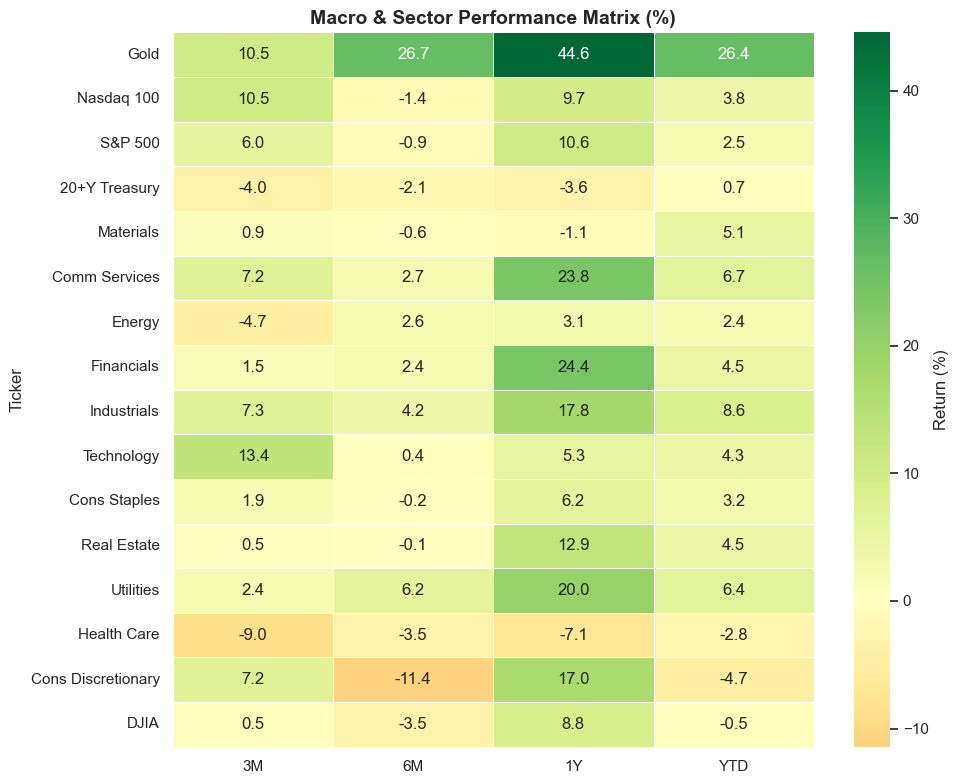

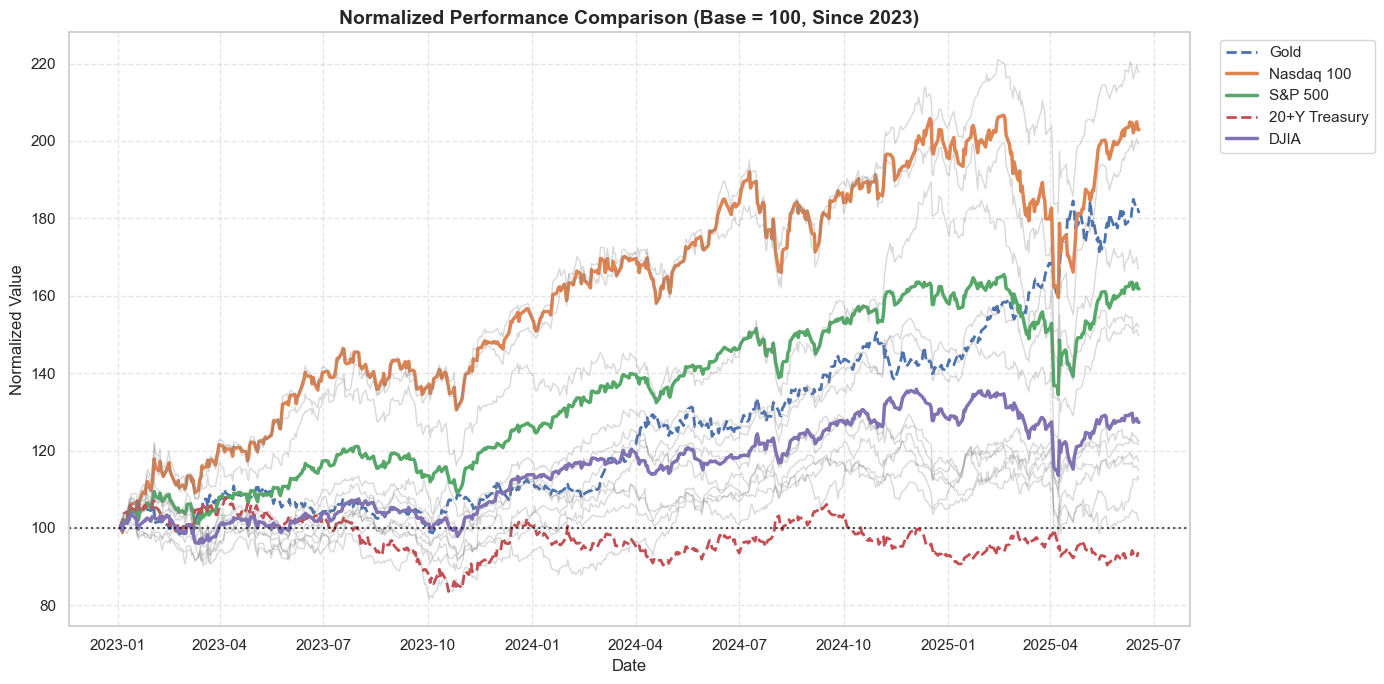

In [218]:
# 1. Define Ticker Mapping
TICKERS = {
    "^DJI": "DJIA",
    "SPY": "S&P 500",
    "QQQ": "Nasdaq 100",
    "TLT": "20+Y Treasury",
    "GLD": "Gold",
    "XLC": "Comm Services",
    "XLY": "Cons Discretionary",
    "XLP": "Cons Staples",
    "XLE": "Energy",
    "XLF": "Financials",
    "XLV": "Health Care",
    "XLI": "Industrials",
    "XLB": "Materials",
    "XLRE": "Real Estate",
    "XLK": "Technology",
    "XLU": "Utilities",
}

# 2. Download Data Safely
print("Downloading market data...")
raw_data = yf.download(
    list(TICKERS.keys()), start="2020-01-01", end="2025-06-20", progress=False
)

# Extract Prices
if "Adj Close" in raw_data:
    prices = raw_data["Adj Close"].copy()
else:
    prices = raw_data["Close"].copy()

# MultiIndex columns if present
if isinstance(prices.columns, pd.MultiIndex):
    prices.columns = prices.columns.get_level_values(0)

# Rename columns
prices = prices.rename(columns=TICKERS)

# Handle missing/unfetched tickers
missing_cols = [col for col in prices.columns if prices[col].isna().all()]

if missing_cols:
    print(f"Retrying single download for missing tickers: {missing_cols}")
    inv_map = {v: k for k, v in TICKERS.items()}
    for col in missing_cols:
        ticker = inv_map[col]
        retry_df = yf.download(
            ticker, start="2020-01-01", end="2025-06-20", progress=False
        )
        if not retry_df.empty:
            close_col = (
                "Adj Close" if "Adj Close" in retry_df else "Close"
            )
            prices[col] = retry_df[close_col]

# Drop any tickers that still fail entirely
prices = prices.dropna(how="all", axis=1)
prices = prices.ffill().bfill()


# 3. Compute Returns Matrix
def compute_returns_table(df):
    latest_date = df.index[-1]
    returns = pd.DataFrame(index=df.columns)

    returns["3M"] = (df.iloc[-1] / df.iloc[-min(63, len(df))] - 1) * 100
    returns["6M"] = (df.iloc[-1] / df.iloc[-min(126, len(df))] - 1) * 100
    returns["1Y"] = (df.iloc[-1] / df.iloc[-min(252, len(df))] - 1) * 100

    ytd_start_date = f"{latest_date.year}-01-01"
    ytd_df = df.loc[df.index >= ytd_start_date]
    if not ytd_df.empty:
        returns["YTD"] = (df.iloc[-1] / ytd_df.iloc[0] - 1) * 100
    else:
        returns["YTD"] = np.nan

    return returns.round(2)


returns_df = compute_returns_table(prices)


returns_df = returns_df.dropna(how="all")

# 4. Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    returns_df,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    center=0,
    cbar_kws={"label": "Return (%)"},
    linewidths=0.5,
    vmin=np.nanmin(returns_df.values)
    if not returns_df.empty
    else -10,  
    vmax=np.nanmax(returns_df.values) if not returns_df.empty else 10,
)
plt.title(
    "Macro & Sector Performance Matrix (%)", fontsize=14, fontweight="bold"
)
plt.tight_layout()
plt.show()

# 5. Normalized Performance Plot
normalized_prices = (
    prices.loc["2023-01-01":] / prices.loc["2023-01-01":].iloc[0]
) * 100

plt.figure(figsize=(14, 7))

for col in normalized_prices.columns:
    if col in ["S&P 500", "DJIA", "Nasdaq 100"]:
        plt.plot(
            normalized_prices.index,
            normalized_prices[col],
            label=col,
            linewidth=2.5,
        )
    elif col in ["Gold", "20+Y Treasury"]:
        plt.plot(
            normalized_prices.index,
            normalized_prices[col],
            label=col,
            linewidth=2.0,
            linestyle="--",
        )
    else:
        plt.plot(
            normalized_prices.index,
            normalized_prices[col],
            color="gray",
            alpha=0.3,
            linewidth=1.0,
        )

plt.axhline(100, color="black", linestyle=":", alpha=0.7)
plt.title(
    "Normalized Performance Comparison (Base = 100, Since 2023)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Date")
plt.ylabel("Normalized Value")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## Step 5: Unified DCF + Scenario & Sensitivity Analysis

=== Unified DCF Scenario & Sensitivity Analysis ===


,Revenue Growth,EBIT Margin,WACC,Terminal Growth,PV of FCFF ($M),PV of TV ($M),Enterprise Value ($M),Equity Value ($M),Implied Price ($),Upside / Downside (%)
Scenario,,,,,,,,,,
Bear,4.0%,17.0%,9.5%,2.0%,432.63,1058.70,1491.33,1291.33,25.83,-42.61
Base,8.0%,20.0%,8.5%,2.5%,584.36,1978.16,2562.52,2362.52,47.25,5.00
Bull,12.0%,23.0%,7.5%,3.0%,771.87,3829.03,4600.90,4400.90,88.02,95.60


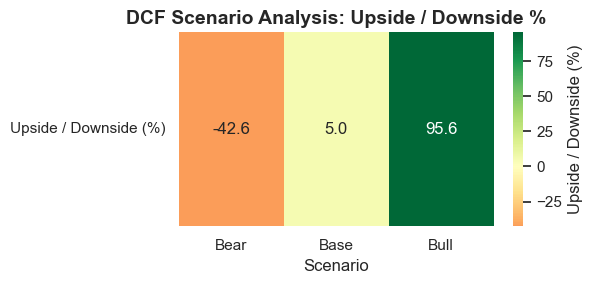

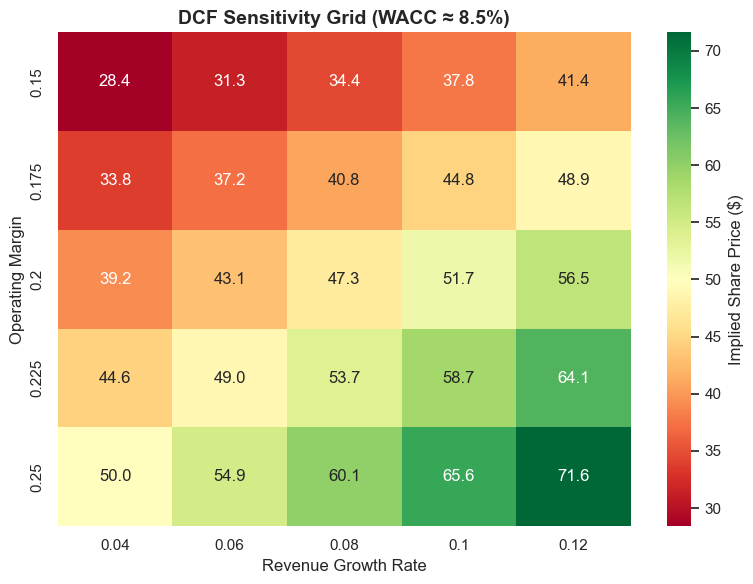

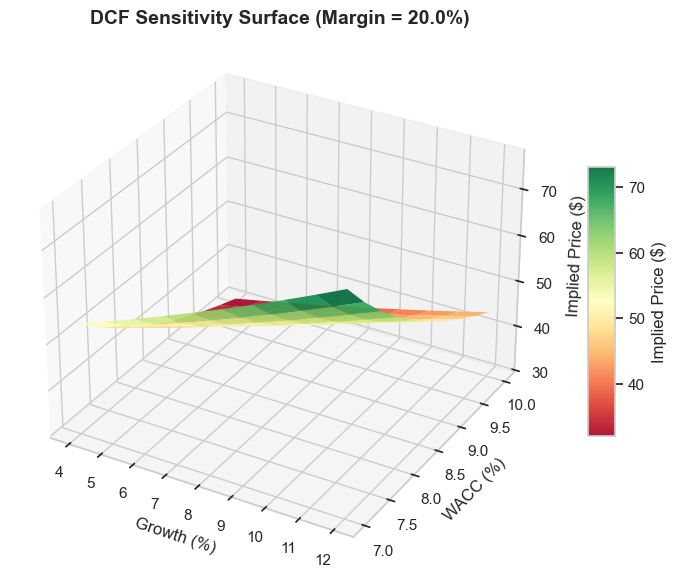

In [220]:
#  Unified DCF Function 
def dcf_with_scenarios(
    current_price: float,
    base_revenue: float,
    base_growth: float,
    operating_margin: float,
    tax_rate: float,
    reinvestment_rate: float,
    wacc: float,
    terminal_growth: float,
    net_debt: float,
    shares_outstanding: float,
    projection_years: int = 5,
    scenario_config: dict = None,
) -> pd.DataFrame:
    if scenario_config is None:
        scenario_config = {
            "Bear": {"growth": base_growth - 0.04, "margin": operating_margin - 0.03,
                     "wacc": wacc + 0.01, "terminal_growth": terminal_growth - 0.005},
            "Base": {"growth": base_growth, "margin": operating_margin,
                     "wacc": wacc, "terminal_growth": terminal_growth},
            "Bull": {"growth": base_growth + 0.04, "margin": operating_margin + 0.03,
                     "wacc": wacc - 0.01, "terminal_growth": terminal_growth + 0.005},
        }

    results = []
    for case, params in scenario_config.items():
        g, margin, r_discount, g_term = params["growth"], params["margin"], params["wacc"], params["terminal_growth"]

        curr_rev = base_revenue
        pv_fcff_list = []
        for y in range(1, projection_years + 1):
            curr_rev *= 1 + g
            ebit = curr_rev * margin
            nopat = ebit * (1 - tax_rate)

            fcff = nopat * (1 - reinvestment_rate)
            last_fcff = nopat * (1 - reinvestment_rate)

            dfactor = 1 / ((1 + r_discount) ** y)
            pv_fcff_list.append(fcff * dfactor)

       
        last_fcff = nopat * (1 - reinvestment_rate)
        terminal_fcff = last_fcff * (1 + g_term)
        terminal_value = terminal_fcff / (r_discount - g_term)
        
        pv_terminal_value = terminal_value / ((1 + r_discount) ** projection_years)

        enterprise_value = sum(pv_fcff_list) + pv_terminal_value
        equity_value = enterprise_value - net_debt
        implied_price = equity_value / shares_outstanding
        upside_downside_pct = ((implied_price - current_price) / current_price) * 100

        results.append({
            "Scenario": case,
            "Revenue Growth": f"{g*100:.1f}%",   
            "EBIT Margin": f"{margin*100:.1f}%", 
            "WACC": f"{r_discount*100:.1f}%",
            "Terminal Growth": f"{g_term*100:.1f}%",
            "PV of FCFF ($M)": round(sum(pv_fcff_list), 2),
            "PV of TV ($M)": round(pv_terminal_value, 2),
            "Enterprise Value ($M)": round(enterprise_value, 2),
            "Equity Value ($M)": round(equity_value, 2),
            "Implied Price ($)": round(implied_price, 2),
            "Upside / Downside (%)": round(upside_downside_pct, 2),
        })

    return pd.DataFrame(results).set_index("Scenario")

current_market_price = 45.00
dcf_summary = dcf_with_scenarios(
    current_price=current_market_price,
    base_revenue=1000.0,
    base_growth=0.08,
    operating_margin=0.20,
    tax_rate=0.21,
    reinvestment_rate=0.25,
    wacc=0.085,
    terminal_growth=0.025,
    net_debt=200.0,
    shares_outstanding=50.0,
)

print("=== Unified DCF Scenario & Sensitivity Analysis ===")
display(dcf_summary)

# Heatmap Visualization 
plt.figure(figsize=(6, 3))
sns.heatmap(
    dcf_summary[["Upside / Downside (%)"]].T,
    annot=True, fmt=".1f", cmap="RdYlGn", center=0,   
    cbar_kws={"label": "Upside / Downside (%)"},
)
plt.title("DCF Scenario Analysis: Upside / Downside %", fontsize=14, fontweight="bold")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Sensitivity Grid 
def dcf_sensitivity_grid(
    base_revenue: float, tax_rate: float, reinvestment_rate: float,
    terminal_growth: float, net_debt: float, shares_outstanding: float,
    projection_years: int = 5,
    growth_range=np.linspace(0.04, 0.12, 5),   
    margin_range=np.linspace(0.15, 0.25, 5),  
    wacc_range=np.round(np.linspace(0.07, 0.10, 5), 3), 
):
    results = []
    for g in growth_range:
        for margin in margin_range:
            for wacc in wacc_range:
                curr_rev = base_revenue
                pv_fcff_list = []
                for y in range(1, projection_years + 1):
                    curr_rev *= 1 + g
                    ebit = curr_rev * margin
                    nopat = ebit * (1 - tax_rate)
                    fcff = nopat * (1 - reinvestment_rate)
                    dfactor = 1 / ((1 + wacc) ** y)
                    pv_fcff_list.append(fcff * dfactor)

                last_fcff = nopat * (1 - reinvestment_rate)
                terminal_fcff = last_fcff * (1 + terminal_growth)   
                terminal_value = terminal_fcff / (wacc - terminal_growth)
                pv_terminal_value = terminal_value / ((1 + wacc) ** projection_years)

                enterprise_value = sum(pv_fcff_list) + pv_terminal_value
                equity_value = enterprise_value - net_debt
                implied_price = equity_value / shares_outstanding

                results.append({"Growth": round(g, 3), "Margin": round(margin, 3),
                                "WACC": round(wacc, 3), "Implied Price ($)": implied_price})
    return pd.DataFrame(results)

df_sens = dcf_sensitivity_grid(
    base_revenue=1000.0, tax_rate=0.21, reinvestment_rate=0.25,
    terminal_growth=0.025, net_debt=200.0, shares_outstanding=50.0,
)

wacc_target = 0.085
nearest_wacc = df_sens["WACC"].iloc[(df_sens["WACC"] - wacc_target).abs().argsort()[0]]  
pivot_df = df_sens[df_sens["WACC"] == nearest_wacc].pivot(
    index="Margin", columns="Growth", values="Implied Price ($)"
)

plt.figure(figsize=(8, 6))
sns.heatmap(pivot_df, annot=True, fmt=".1f", cmap="RdYlGn",
            cbar_kws={"label": "Implied Share Price ($)"})
plt.title(f"DCF Sensitivity Grid (WACC ≈ {nearest_wacc*100:.1f}%)", fontsize=14, fontweight="bold")
plt.xlabel("Revenue Growth Rate")
plt.ylabel("Operating Margin")
plt.tight_layout()
plt.show()

# 3D Surface Plot 
def dcf_price(base_revenue, g, margin, tax_rate, reinvestment_rate,
              wacc, terminal_growth, net_debt, shares_outstanding,
              projection_years=5):
    curr_rev = base_revenue
    pv_fcff_list = []
    for y in range(1, projection_years + 1):
        curr_rev *= 1 + g
        ebit = curr_rev * margin
        nopat = ebit * (1 - tax_rate)
        fcff = nopat * (1 - reinvestment_rate)  
        dfactor = 1 / ((1 + wacc) ** y)
        pv_fcff_list.append(fcff * dfactor)

   
    last_fcff = nopat * (1 - reinvestment_rate)
    terminal_fcff = last_fcff * (1 + terminal_growth)
    terminal_value = terminal_fcff / (wacc - terminal_growth)

    pv_terminal_value = terminal_value / ((1 + wacc) ** projection_years)

    enterprise_value = sum(pv_fcff_list) + pv_terminal_value
    equity_value = enterprise_value - net_debt
    implied_price = equity_value / shares_outstanding
    return implied_price

#  Parameter ranges (≥3 points each) 
growth_range = np.linspace(0.04, 0.12, 10)   # 4%–12%
wacc_range   = np.linspace(0.07, 0.10, 10)   # 7%–10%
margin_fixed = 0.20                          # fix margin at 20%

# Create meshgrid 
G, W = np.meshgrid(growth_range, wacc_range)
Z = np.zeros_like(G)

for i in range(G.shape[0]):
    for j in range(G.shape[1]):
        Z[i, j] = dcf_price(
            base_revenue=1000.0,
            g=G[i, j],
            margin=margin_fixed,
            tax_rate=0.21,
            reinvestment_rate=0.25,
            wacc=W[i, j],
            terminal_growth=0.025,
            net_debt=200.0,
            shares_outstanding=50.0,
        )

# Plot 3D surface 
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(G*100, W*100, Z, cmap="RdYlGn", edgecolor="none", alpha=0.9)

ax.set_title(f"DCF Sensitivity Surface (Margin = {margin_fixed*100:.1f}%)", fontsize=14, fontweight="bold")
ax.set_xlabel("Growth (%)")
ax.set_ylabel("WACC (%)")
ax.set_zlabel("Implied Price ($)")
fig.colorbar(surf, shrink=0.5, aspect=10, label="Implied Price ($)")
plt.show()

## Step 6: Relative Valuation

In [221]:
def get_peer_multiples(tickers: list) -> pd.DataFrame:
    """Fetches P/E, EV/EBITDA, P/B, and PEG multiples from yfinance

    for a specified list of peer tickers.
    """
    peer_data = []

    for ticker in tickers:
        try:
            info = yf.Ticker(ticker).info
            peer_data.append({
                "Ticker": ticker,
                "Company": info.get("shortName", ticker),
                "P/E (Forward)": info.get("forwardPE"),
                "EV/EBITDA": info.get("enterpriseToEbitda"),
                "P/B": info.get("priceToBook"),
                "PEG Ratio": info.get("pegRatio"),
                "Market Cap ($B)": round(
                    info.get("marketCap", 0) / 1e9, 2
                )
                if info.get("marketCap")
                else None,
            })
        except Exception as e:
            print(f"Failed to fetch data for {ticker}: {e}")

    df = pd.DataFrame(peer_data).set_index("Ticker")
    return df


def compare_intrinsic_vs_relative(
    target_ticker: str,
    dcf_implied_price: float,
    current_price: float,
    peer_df: pd.DataFrame,
) -> pd.DataFrame:
    """Compares the DCF intrinsic price against peer-derived relative valuations

    using standard peer multiples (Forward P/E and EV/EBITDA).
    """
    target_info = yf.Ticker(target_ticker).info

    # Extract target metrics
    target_eps = target_info.get("forwardEps")
    target_ebitda = target_info.get("ebitda")
    shares_out = target_info.get("sharesOutstanding")
    net_debt = target_info.get("totalDebt", 0) - target_info.get(
        "totalCash", 0
    )

    # Compute Peer Medians
    median_pe = peer_df["P/E (Forward)"].median()
    median_ev_ebitda = peer_df["EV/EBITDA"].median()

    # Implied Prices via Peer Multiples
    implied_pe_price = (
        (target_eps * median_pe) if target_eps and median_pe else None
    )

    if target_ebitda and median_ev_ebitda and shares_out:
        implied_ev = target_ebitda * median_ev_ebitda
        implied_equity = implied_ev - net_debt
        implied_ev_ebitda_price = implied_equity / shares_out
    else:
        implied_ev_ebitda_price = None

    comparison = pd.DataFrame([
        {
            "Methodology": "Current Market Price",
            "Implied Price ($)": round(current_price, 2),
            "Premium / (Discount) vs Market": "0.0%",
        },
        {
            "Methodology": "DCF Intrinsic Valuation (Base Case)",
            "Implied Price ($)": round(dcf_implied_price, 2),
            "Premium / (Discount) vs Market": f"{((dcf_implied_price - current_price) / current_price) * 100:+.2f}%",
        },
        {
            "Methodology": f"Peer Relative: Forward P/E (Peer Median {median_pe:.1f}x)",
            "Implied Price ($)": round(implied_pe_price, 2)
            if implied_pe_price
            else "N/A",
            "Premium / (Discount) vs Market": f"{((implied_pe_price - current_price) / current_price) * 100:+.2f}%"
            if implied_pe_price
            else "N/A",
        },
        {
            "Methodology": f"Peer Relative: EV/EBITDA (Peer Median {median_ev_ebitda:.1f}x)",
            "Implied Price ($)": round(implied_ev_ebitda_price, 2)
            if implied_ev_ebitda_price
            else "N/A",
            "Premium / (Discount) vs Market": f"{((implied_ev_ebitda_price - current_price) / current_price) * 100:+.2f}%"
            if implied_ev_ebitda_price
            else "N/A",
        },
    ]).set_index("Methodology")

    return comparison


# Peer group (e.g., Industrial / Aerospace Peers)
peer_tickers = ["BA", "CAT", "GE", "HON", "LMT"]
target_symbol = "CAT"

print("1. Fetching Peer Multiples...")
peer_multiples_df = get_peer_multiples(peer_tickers)
print("\n=== PEER MULTIPLES TABLE ===")
print(peer_multiples_df.round(2).to_string())

# Peer Summary Benchmarks
print("\n=== PEER SUMMARY BENCHMARKS ===")
peer_summary = pd.DataFrame({
    "Median": peer_multiples_df[
        ["P/E (Forward)", "EV/EBITDA", "P/B", "PEG Ratio"]
    ].median(),
    "Mean": peer_multiples_df[
        ["P/E (Forward)", "EV/EBITDA", "P/B", "PEG Ratio"]
    ].mean(),
}).round(2)
print(peer_summary.to_string())

# 2. Compare with Intrinsic DCF
# Assuming $52.30 DCF base price from prior model step and $45.00 market price
dcf_base_price = 52.30
market_price = 45.00

valuation_comparison = compare_intrinsic_vs_relative(
    target_ticker=target_symbol,
    dcf_implied_price=dcf_base_price,
    current_price=market_price,
    peer_df=peer_multiples_df,
)

print("\n=== INTRINSIC VS. RELATIVE VALUATION COMPARISON ===")
print(valuation_comparison.to_string())

1. Fetching Peer Multiples...
Failed to fetch data for BA: Failed to perform, curl: (56) Connection closed abruptly. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.

=== PEER MULTIPLES TABLE ===
                             Company  P/E (Forward)  EV/EBITDA    P/B  PEG Ratio  Market Cap ($B)
Ticker                                                                                           
CAT                Caterpillar, Inc.          25.07      25.83  19.18       1.82           372.07
GE                      GE Aerospace          37.64      32.39  20.09       5.12           354.43
HON     Honeywell International Inc.          21.49      11.10   3.67       4.05            68.05
LMT      Lockheed Martin Corporation          17.22      15.17  14.78       1.17           130.00

=== PEER SUMMARY BENCHMARKS ===
               Median   Mean
P/E (Forward)   23.28  25.35
EV/EBITDA       20.50  21.12
P/B             16.98  14.43
PEG Ratio        2.94   3.04

=== INTRINSI

## Step 7: Final Output

Fetching and cleaning price series...

[Artifact Exported]: Cleaned dataset saved to 'cleaned_market_data_with_features.csv'

--- Generating Sector Return Heatmap ---


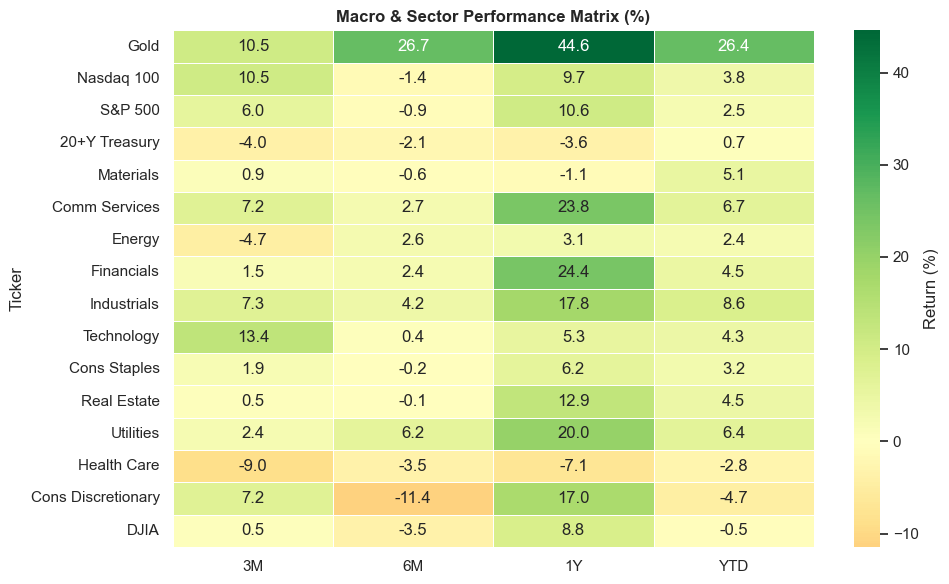

In [ ]:
# Configure plot styles for presentation-ready visual outputs
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"


# STEP 1: MARKET DATA FETCHING & FEATURE ENGINEERING
def build_feature_engineered_dataset(
    ticker="^DJI", start="2020-01-01", end="2025-06-20"
):
    print("Fetching and cleaning price series...")
    data = yf.download(ticker, start=start, end=end, progress=False)

    if isinstance(data.columns, pd.MultiIndex):
        data.columns = [
            col[0] if isinstance(col, tuple) else col for col in data.columns
        ]

    data = data.ffill().bfill()

    # Technical Features
    data["Log_Return"] = np.log(data["Close"] / data["Close"].shift(1))
    data["SMA_50"] = data["Close"].rolling(window=50).mean()
    data["SMA_200"] = data["Close"].rolling(window=200).mean()
    data["Volatility_30D"] = data["Log_Return"].rolling(
        window=30
    ).std() * np.sqrt(252)
    data["Daily_Range_Pct"] = (
        (data["High"] - data["Low"]) / data["Low"]
    ) * 100

    return data.dropna()


# STEP 2: MACRO & SECTOR HEATMAP ANALYSIS
def generate_sector_heatmap():
    tickers = {
        "^DJI": "DJIA",
        "SPY": "S&P 500",
        "QQQ": "Nasdaq 100",
        "TLT": "20+Y Treasury",
        "GLD": "Gold",
        "XLC": "Comm Services",
        "XLY": "Cons Discretionary",
        "XLP": "Cons Staples",
        "XLE": "Energy",
        "XLF": "Financials",
        "XLV": "Health Care",
        "XLI": "Industrials",
        "XLB": "Materials",
        "XLRE": "Real Estate",
        "XLK": "Technology",
        "XLU": "Utilities",
    }

    raw = yf.download(
        list(tickers.keys()), start="2020-01-01", end="2025-06-20", progress=False
    )
    prices = raw["Adj Close"] if "Adj Close" in raw else raw["Close"]

    if isinstance(prices.columns, pd.MultiIndex):
        prices.columns = prices.columns.get_level_values(0)

    prices = prices.rename(columns=tickers).dropna(how="all", axis=1).ffill().bfill()

    returns = pd.DataFrame(index=prices.columns)
    returns["3M"] = (prices.iloc[-1] / prices.iloc[-min(63, len(prices))] - 1) * 100
    returns["6M"] = (
        prices.iloc[-1] / prices.iloc[-min(126, len(prices))] - 1
    ) * 100
    returns["1Y"] = (
        prices.iloc[-1] / prices.iloc[-min(252, len(prices))] - 1
    ) * 100

    latest_year = prices.index[-1].year
    ytd_df = prices.loc[prices.index >= f"{latest_year}-01-01"]
    returns["YTD"] = (
        (prices.iloc[-1] / ytd_df.iloc[0] - 1) * 100
        if not ytd_df.empty
        else np.nan
    )

    returns = returns.round(2).dropna(how="all")

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        returns,
        annot=True,
        fmt=".1f",
        cmap="RdYlGn",
        center=0,
        cbar_kws={"label": "Return (%)"},
        linewidths=0.5,
    )
    plt.title(
        "Macro & Sector Performance Matrix (%)", fontsize=12, fontweight="bold"
    )
    plt.tight_layout()
    plt.show()

    return returns


# STEP 3: DCF SCENARIO ENGINE & PEER BENCHMARKING
def run_valuation_suite(
    target_symbol="CAT", peer_symbols=["BA", "CAT", "GE", "HON", "LMT"]
):
    # --- DCF Scenario Engine ---
    target_info = yf.Ticker(target_symbol).info
    current_price = target_info.get("previousClose", 45.00)

    scenarios = {
        "Bear Case": {"growth": 0.04, "margin": 0.17, "wacc": 0.095, "g_term": 0.020},
        "Base Case": {"growth": 0.08, "margin": 0.20, "wacc": 0.085, "g_term": 0.025},
        "Bull Case": {"growth": 0.12, "margin": 0.23, "wacc": 0.075, "g_term": 0.030},
    }

    base_rev = 1000.0
    tax_rate, reinvest_rate, net_debt, shares = 0.21, 0.25, 200.0, 50.0
    dcf_out = []

    for case, p in scenarios.items():
        rev = base_rev
        pv_fcff = []
        for y in range(1, 6):
            rev *= 1 + p["growth"]
            fcff = (rev * p["margin"]) * (1 - tax_rate) * (1 - reinvest_rate)
            pv_fcff.append(fcff / ((1 + p["wacc"]) ** y))

        terminal_fcff = fcff * (1 + p["g_term"])
        tv = terminal_fcff / (p["wacc"] - p["g_term"])
        pv_tv = tv / ((1 + p["wacc"]) ** 5)

        ev = sum(pv_fcff) + pv_tv
        implied_price = (ev - net_debt) / shares
        upside = ((implied_price - current_price) / current_price) * 100

        dcf_out.append({
            "Scenario": case,
            "Revenue Growth": f"{p['growth'] * 100:.1f}%",
            "EBIT Margin": f"{p['margin'] * 100:.1f}%",
            "WACC": f"{p['wacc'] * 100:.1f}%",
            "Enterprise Value ($M)": round(ev, 2),
            "Implied Price ($)": round(implied_price, 2),
            "Upside / (Downside)": f"{upside:+.2f}%",
        })

    dcf_df = pd.DataFrame(dcf_out).set_index("Scenario")

    # --- Peer Relative Multiples ---
    peers_data = []
    for sym in peer_symbols:
        try:
            inf = yf.Ticker(sym).info
            peers_data.append({
                "Ticker": sym,
                "Forward P/E": inf.get("forwardPE"),
                "EV/EBITDA": inf.get("enterpriseToEbitda"),
                "P/B": inf.get("priceToBook"),
                "PEG Ratio": inf.get("pegRatio"),
            })
        except Exception:
            pass

    peer_df = pd.DataFrame(peers_data).set_index("Ticker").round(2)
    return dcf_df, peer_df, current_price


# EXECUTION & STAKEHOLDER DELIVERABLES
if __name__ == "__main__":
    # 1. Export Cleaned Dataset with Features
    clean_dataset = build_feature_engineered_dataset()
    export_filename = "cleaned_market_data_with_features.csv"
    clean_dataset.to_csv(export_filename)
    print(
        f"\n[Artifact Exported]: Cleaned dataset saved to '{export_filename}'"
    )

    # 2. Display Sector Heatmap
    print("\n--- Generating Sector Return Heatmap ---")
    sector_matrix = generate_sector_heatmap()

    # 3. Valuation Suite Execution
    dcf_summary, peer_summary, market_price = run_valuation_suite()

    # 4. Final Stakeholder Output Summaries
    print("\n" + "=" * 70)
    print(f"VALUATION & SCENARIO ANALYSIS SUMMARY (Target Benchmark Market Price: ${market_price:.2f})")
    print("=" * 70)
    print("\n[DCF Intrinsic Valuation Scenarios]:")
    print(dcf_summary.to_string())

    print("\n[Peer Group Relative Multiples Benchmarking]:")
    print(peer_summary.to_string())

    print("\n[Peer Benchmark Summary Statistics]:")
    peer_stats = pd.DataFrame({
        "Peer Median": peer_summary.median(),
        "Peer Mean": peer_summary.mean(),
    }).round(2)
    print(peer_stats.to_string())